# YOLOv8n Elderly Safety Action Detector — Training Notebook

**Goal:** fine-tune a YOLOv8**n** (nano) object detector to recognize a small set
of safety-relevant human actions/states — `standing`, `falling`,
`smoking`, `drinking`, `fire` — for deployment on edge hardware (e.g. a
Raspberry Pi 5 running ONNX Runtime).

> **Before you run this:** no single public dataset covers all of these classes
> together. This notebook **merges several source datasets**
> (each covering one or two of your classes) into one unified YOLO-format
> dataset, remaps their class indices, then trains on the merged set. You supply
> the source datasets in the `SOURCES` config below — see the markdown cell
> in **Section 2** for exactly what's expected.

### Notebook sections
1. Environment setup
2. Dataset acquisition & class-unification
3. Dataset sanity checks
4. Training configuration
5. Training
6. Evaluation & diagnostics
7. Export (ONNX, for edge deployment)
8. Packaging outputs (with a fix for Kaggle's "no output files" issue)

### Kaggle settings you need before running
- **Settings → Accelerator → GPU T4 x2** (or any available GPU) — training on CPU will be far too slow.
- **Settings → Internet → On** — required to `pip install` and to download source datasets.
- If you're pulling datasets from Roboflow, add your API key as a **Kaggle Secret** named `ROBOFLOW_API_KEY`
  (Add-ons → Secrets in the notebook editor) rather than pasting it in plaintext.




## 1. Environment setup

In [1]:
# Install/upgrade the packages we need. Kaggle images already ship torch + CUDA,
# so we only add the higher-level libraries.
!pip install -q "ultralytics>=8.3.0" roboflow pyyaml --upgrade

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 276.9/276.9 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 104.5 MB/s eta 0:00:00


In [2]:
import os
import sys
import shutil
import random
import glob
from pathlib import Path
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import cv2
import torch

from ultralytics import YOLO

print(f"Python      : {sys.version.split()[0]}")
print(f"PyTorch     : {torch.__version__}")
print(f"CUDA avail. : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU         : {torch.cuda.get_device_name(0)}")
else:
    print("!! No GPU detected — go to Settings > Accelerator and enable a GPU before training.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Python      : 3.12.13
PyTorch     : 2.10.0+cu128
CUDA avail. : True
GPU         : Tesla T4


In [3]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

## 2. Dataset acquisition & class unification

### What this section expects
List every source dataset you want to merge in `SOURCES` below. Each entry needs:

- `name` — a short label, used only for logging.
- `download_fn` — how to fetch it. Two ready-made helpers are provided:
  `download_roboflow(...)` (Roboflow Universe projects, YOLOv8 export format)
  and `use_kaggle_input(...)` (a dataset you've already attached to this
  notebook via **Add Data**, expected to already be in YOLO format).
- `class_map` — a dict mapping **that dataset's own class names** to **your
  unified class names** (defined in `UNIFIED_CLASSES` below). Any class not
  listed here is dropped from that source.

### Sources pre-filled below (edit/replace as needed)

| Source | Provides | Notes |
|---|---|---|
| `human-action-recognition-x6cml` | `standing`, `falling` | 10k images; several fall variants (`Fall_down`, `Nearly_fall`, `Fall-Detected`) all merged into one `falling` class |
| `employee-productivity-2.0-whbwv` | `smoking` | ~9.8k images, workplace CCTV context; `Cigarette`/`Smoke` merged into `smoking` |
| `smoking-and-drinking-detection` | `smoking` | 1k images, supplemental smoking examples |
| `fire-dataset-for-yolov8` | `fire` | 3,996 images, indoor-optimized, single `fire` class |
| `drinking-1700` | `drinking` | 1,700 images, bottle-centric drinking action |

You still need a **Roboflow API key** stored as a Kaggle Secret named
`ROBOFLOW_API_KEY` (Add-ons → Secrets) for the `download_roboflow(...)` calls
to work. Free-tier Roboflow accounts can download all five datasets above.

> **Before running:** double-check the `version` number for each source on its
> Roboflow project page, and after the merge step (Section 2, last cell)
> verify the printed `Source Raw Classes` for each source match the keys used
> in its `class_map` exactly (case-sensitive) — this is the most common
> reason a source silently contributes 0 images.
>
> Some source datasets ship without a validation split. If that leaves a
> class with 0 boxes in `val`, the merge step automatically moves a sample
> of that class's train images into `val` so validation metrics stay
> meaningful — see the cell immediately after the merge for details.


In [4]:
# ── Unified class taxonomy — edit this to match your actual target classes ──
UNIFIED_CLASSES = ["standing", "falling", "smoking", "drinking", "fire"]

RAW_DATASETS_DIR = Path("/kaggle/working/raw_datasets")
MERGED_DATASET_DIR = Path("/kaggle/working/dataset")
RAW_DATASETS_DIR.mkdir(parents=True, exist_ok=True)

print("Unified classes:", UNIFIED_CLASSES)

Unified classes: ['standing', 'falling', 'smoking', 'drinking', 'fire']


In [5]:
def get_roboflow_api_key() -> str:
    """Fetch the Roboflow API key from Kaggle Secrets (preferred) or an env var."""
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
    except Exception:
        key = os.environ.get("ROBOFLOW_API_KEY")
        if not key:
            raise RuntimeError(
                "No Roboflow API key found. Add it as a Kaggle Secret named "
                "'ROBOFLOW_API_KEY' (Add-ons > Secrets), or set the "
                "ROBOFLOW_API_KEY environment variable."
            )
        return key


def download_roboflow(workspace: str, project: str, version: int, fmt: str = "yolov8") -> Path:
    """Download a Roboflow Universe dataset in YOLO format. Returns the local path."""
    from roboflow import Roboflow

    rf = Roboflow(api_key=get_roboflow_api_key())
    ds = (
        rf.workspace(workspace)
        .project(project)
        .version(version)
        .download(fmt, location=str(RAW_DATASETS_DIR / f"{project}_v{version}"))
    )
    return Path(ds.location)


def use_kaggle_input(dataset_dir: str) -> Path:
    """Point at a dataset already attached to this notebook via 'Add Data'.
    Expected to be in standard YOLO format (images/ + labels/ + data.yaml)."""
    path = Path("/kaggle/input") / dataset_dir
    if not path.exists():
        raise FileNotFoundError(
            f"'{dataset_dir}' not found under /kaggle/input — attach it via Add Data first."
        )
    return path

In [6]:
# ── Data sources ─────────────────────────────────────────────────────────
# All five Roboflow Universe datasets below are free-tier accessible.
# Adjust `version` numbers if a project has been updated since this notebook
# was written — check the dataset's Roboflow page for its current version.

SOURCES = [
    dict(
        name="human_action_recognition",
        download_fn=lambda: download_roboflow(
            workspace="le-quy-don-high-school-for-gifted-students-bllby",
            project="human-action-recognition-x6cml",
            version=1,
        ),
        class_map={
            "standing": "standing",
            "Standing": "standing",
            "Fall-Detected": "falling",
            "Fall_down": "falling",
            "Nearly_fall": "falling",
            "falling": "falling",
        },
    ),
    dict(
        name="employee_productivity",
        download_fn=lambda: download_roboflow(
            workspace="bahadur-pelqz",
            project="employee-productivity-2.0-whbwv",
            version=1,
        ),
        class_map={
            "Cigarette": "smoking",
            "Smoke": "smoking",
        },
    ),
    dict(
        name="smoking_drinking",
        download_fn=lambda: download_roboflow(
            workspace="yolo-dataset-rtznj",
            project="smoking-and-drinking-detection",
            version=2,
        ),
        class_map={
            "smoking": "smoking",
        },
    ),
    dict(
        name="fire_indoor",
        download_fn=lambda: download_roboflow(
            workspace="aj-garcia-736tc",
            project="fire-dataset-for-yolov8",
            version=2,
        ),
        class_map={
            "fire": "fire",
        },
    ),
    dict(
        name="drinking_bottle",
        download_fn=lambda: download_roboflow(
            workspace="celebal-nvwvr",
            project="drinking-1700",
            version=1,
        ),
        class_map={
            "Drinking": "drinking",
            "drinking": "drinking",
        },
    ),
]

if not SOURCES:
    raise ValueError(
        "SOURCES is empty. Fill in at least one dataset entry above before "
        "continuing — see the markdown cell for the expected format."
    )

In [7]:
def merge_split(
    dataset_path: Path,
    split: str,
    out_split_name: str,
    source_class_names: list[str],
    class_map: dict[str, str],
    unified_classes: list[str],
    out_dir: Path,
) -> int:
    """
    Copies images and remaps class bounding boxes from a source dataset split 
    into a globally unified taxonomy split. Dropped or unmapped classes are filtered out.
    
    Args:
        dataset_path (Path): Root directory of the downloaded source dataset.
        split (str): Name of the split in the source directory (e.g., 'valid').
        out_split_name (str): Unified name for the output split destination (e.g., 'val').
        source_class_names (list[str]): List of class names in the source dataset.
        class_map (dict[str, str]): Mapping from source class name to unified class name.
        unified_classes (list[str]): Complete targeted taxonomy ordered list.
        out_dir (Path): Destination root path for the merged dataset.
        
    Returns:
        int: Total number of valid images successfully processed and copied.
    """
    img_dir = dataset_path / split / "images"
    lbl_dir = dataset_path / split / "labels"
    if not img_dir.exists():
        return 0

    # Ensure output directories match the unified split naming schema (e.g., 'val')
    out_img_dir = out_dir / out_split_name / "images"
    out_lbl_dir = out_dir / out_split_name / "labels"
    out_img_dir.mkdir(parents=True, exist_ok=True)
    out_lbl_dir.mkdir(parents=True, exist_ok=True)

    # Build old_class_id to new_class_id index lookup table
    id_remap: dict[int, int | None] = {}
    for old_id, old_name in enumerate(source_class_names):
        new_name = class_map.get(old_name)
        id_remap[old_id] = unified_classes.index(new_name) if new_name else None

    copied = 0
    for img_path in img_dir.glob("*"):
        if img_path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
            continue
            
        lbl_path = lbl_dir / f"{img_path.stem}.txt"
        if not lbl_path.exists():
            continue

        remapped_lines = []
        with open(lbl_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                old_id = int(parts[0])
                new_id = id_remap.get(old_id)
                if new_id is None:
                    continue  # Filter out out-of-taxonomy classes
                remapped_lines.append(" ".join([str(new_id)] + parts[1:]))

        if not remapped_lines:
            continue  # Avoid copying images with empty bounding boxes after filtering

        # Prevent file name collisions by prepending the dataset source name
        dest_stem = f"{dataset_path.name}_{img_path.stem}"
        shutil.copy(img_path, out_img_dir / f"{dest_stem}{img_path.suffix}")
        with open(out_lbl_dir / f"{dest_stem}.txt", "w") as f:
            f.write("\n".join(remapped_lines))
        copied += 1

    return copied

In [8]:
from pathlib import Path
import yaml

def read_source_class_names(dataset_path: Path) -> list[str]:
    """
    Read class names from a YOLO dataset.yaml file.
    """
    yaml_path = dataset_path / "data.yaml"

    if not yaml_path.exists():
        raise FileNotFoundError(f"data.yaml not found: {yaml_path}")

    with open(yaml_path, "r") as f:
        data = yaml.safe_load(f)

    names = data["names"]

    # Roboflow may save names as dict or list
    if isinstance(names, dict):
        names = [names[i] for i in sorted(names)]

    return names

In [9]:
# ── Execute Downloads and Run Unified Dataset Merging Pipeline ─────────────
if MERGED_DATASET_DIR.exists():
    shutil.rmtree(MERGED_DATASET_DIR)

summary_rows = []
for source in SOURCES:
    print(f"\n=== Processing Source: {source['name']} ===")
    ds_path = source["download_fn"]()
    src_classes = read_source_class_names(ds_path)
    print(f"  Source Raw Classes : {src_classes}")
    print(f"  Taxonomy Class Map : {source['class_map']}")
    
    for src_split in ("train", "valid", "test"):
        # Resolve Roboflow's 'valid' nomenclature to standard YOLOv8 'val'
        out_split = "val" if src_split == "valid" else src_split
        
        copied = merge_split(
            dataset_path=ds_path,
            split=src_split,
            out_split_name=out_split,
            source_class_names=src_classes,
            class_map=source["class_map"],
            unified_classes=UNIFIED_CLASSES,
            out_dir=MERGED_DATASET_DIR,
        )
        print(f"  Split Integration: [{src_split}] -> Added {copied} images to [{out_split}]")


=== Processing Source: human_action_recognition ===
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/raw_datasets/human-action-recognition-x6cml_v1 in yolov8:: 100%|██████████| 17732/17732 [00:02<00:00, 8480.43it/s]


  Source Raw Classes : ['Fall-Detected', 'Sit Down', 'falling', 'sitting', 'standing', 'walking']
  Taxonomy Class Map : {'standing': 'standing', 'Standing': 'standing', 'Fall-Detected': 'falling', 'Fall_down': 'falling', 'Nearly_fall': 'falling', 'falling': 'falling'}
  Split Integration: [train] -> Added 4342 images to [train]
  Split Integration: [valid] -> Added 1155 images to [val]
  Split Integration: [test] -> Added 573 images to [test]

=== Processing Source: employee_productivity ===
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/raw_datasets/employee-productivity-2.0-whbwv_v1 in yolov8:: 100%|██████████| 19695/19695 [00:01<00:00, 9911.84it/s] 


  Source Raw Classes : ['Awake', 'Cigarette', 'Person', 'Sit Down', 'Sitting', 'Sleeping', 'Smoke', 'Standing', 'Vape', 'Wakeup', 'Walking', 'sitting', 'standing', 'walking']
  Taxonomy Class Map : {'Cigarette': 'smoking', 'Smoke': 'smoking'}
  Split Integration: [train] -> Added 2910 images to [train]
  Split Integration: [valid] -> Added 261 images to [val]
  Split Integration: [test] -> Added 75 images to [test]

=== Processing Source: smoking_drinking ===
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/raw_datasets/smoking-and-drinking-detection_v2 in yolov8:: 100%|██████████| 2072/2072 [00:00<00:00, 11717.18it/s]


  Source Raw Classes : ['drinking', 'smoking']
  Taxonomy Class Map : {'smoking': 'smoking'}
  Split Integration: [train] -> Added 448 images to [train]
  Split Integration: [valid] -> Added 112 images to [val]
  Split Integration: [test] -> Added 120 images to [test]

=== Processing Source: fire_indoor ===
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/raw_datasets/fire-dataset-for-yolov8_v2 in yolov8:: 100%|██████████| 1572/1572 [00:00<00:00, 5831.17it/s]


  Source Raw Classes : ['fire']
  Taxonomy Class Map : {'fire': 'fire'}
  Split Integration: [train] -> Added 626 images to [train]
  Split Integration: [valid] -> Added 102 images to [val]
  Split Integration: [test] -> Added 52 images to [test]

=== Processing Source: drinking_bottle ===
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/raw_datasets/drinking-1700_v1 in yolov8:: 100%|██████████| 3404/3404 [00:00<00:00, 8811.32it/s]


  Source Raw Classes : ['Drinking']
  Taxonomy Class Map : {'Drinking': 'drinking', 'drinking': 'drinking'}
  Split Integration: [train] -> Added 1190 images to [train]
  Split Integration: [valid] -> Added 0 images to [val]
  Split Integration: [test] -> Added 510 images to [test]


In [10]:
def count_class_boxes(dataset_dir: Path, split: str, class_id: int) -> int:
    """Count boxes for a given class id in a split's label files."""
    lbl_dir = dataset_dir / split / "labels"
    total = 0
    for lbl_path in lbl_dir.glob("*.txt"):
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if parts and int(parts[0]) == class_id:
                    total += 1
    return total


def ensure_val_representation(
    dataset_dir: Path,
    unified_classes: list[str],
    min_fraction: float = 0.15,
    seed: int = SEED,
) -> None:
    """
    Guarantees every class has at least some representation in the val split.

    Some source datasets ship without a validation split, which can leave a
    class with 0 val boxes if it depends entirely on that source. When that
    happens, a random sample of train images containing the affected class
    is moved into val (image + label together) so validation metrics for
    that class are meaningful during training.
    """
    rng = random.Random(seed)
    train_lbl_dir = dataset_dir / "train" / "labels"
    train_img_dir = dataset_dir / "train" / "images"
    val_lbl_dir = dataset_dir / "val" / "labels"
    val_img_dir = dataset_dir / "val" / "images"
    val_lbl_dir.mkdir(parents=True, exist_ok=True)
    val_img_dir.mkdir(parents=True, exist_ok=True)

    for cls_id, cls_name in enumerate(unified_classes):
        if count_class_boxes(dataset_dir, "val", cls_id) > 0:
            continue

        candidates = []
        for lbl_path in train_lbl_dir.glob("*.txt"):
            with open(lbl_path) as f:
                class_ids = [int(line.strip().split()[0]) for line in f if line.strip()]
            if cls_id in class_ids:
                candidates.append(lbl_path)

        if not candidates:
            print(f"[WARN] '{cls_name}' has 0 boxes in both val and train — check SOURCES/class_map.")
            continue

        n_move = max(1, int(len(candidates) * min_fraction))
        chosen = rng.sample(candidates, min(n_move, len(candidates)))

        for lbl_path in chosen:
            for ext in [".jpg", ".jpeg", ".png", ".JPG", ".PNG"]:
                img_path = train_img_dir / f"{lbl_path.stem}{ext}"
                if img_path.exists():
                    shutil.move(str(img_path), val_img_dir / img_path.name)
                    break
            shutil.move(str(lbl_path), val_lbl_dir / lbl_path.name)

        print(f"[INFO] '{cls_name}' had 0 val boxes — moved {len(chosen)} images from train to val.")


ensure_val_representation(MERGED_DATASET_DIR, UNIFIED_CLASSES)

[INFO] 'drinking' had 0 val boxes — moved 178 images from train to val.


In [11]:
def rebalance_test_to_train(
    dataset_dir: Path,
    unified_classes: list[str],
    max_test_fraction: float = 0.20,
    seed: int = SEED,
) -> None:
    """
    If a class's test-split share of its total boxes exceeds max_test_fraction,
    move a random sample of its pure test images back into train until the
    share is roughly back in line with the other classes.
    """
    rng = random.Random(seed)
    train_lbl_dir = dataset_dir / "train" / "labels"
    train_img_dir = dataset_dir / "train" / "images"
    test_lbl_dir = dataset_dir / "test" / "labels"
    test_img_dir = dataset_dir / "test" / "images"

    for cls_id, cls_name in enumerate(unified_classes):
        train_n = count_class_boxes(dataset_dir, "train", cls_id)
        val_n = count_class_boxes(dataset_dir, "val", cls_id)
        test_n = count_class_boxes(dataset_dir, "test", cls_id)
        total = train_n + val_n + test_n
        if total == 0 or test_n / total <= max_test_fraction:
            continue

        target_test_n = int(total * max_test_fraction)
        n_to_move = test_n - target_test_n

        candidates = []
        for lbl_path in test_lbl_dir.glob("*.txt"):
            with open(lbl_path) as f:
                class_ids = [int(line.strip().split()[0]) for line in f if line.strip()]
            if cls_id in class_ids:
                candidates.append(lbl_path)

        chosen = rng.sample(candidates, min(n_to_move, len(candidates)))
        for lbl_path in chosen:
            for ext in [".jpg", ".jpeg", ".png", ".JPG", ".PNG"]:
                img_path = test_img_dir / f"{lbl_path.stem}{ext}"
                if img_path.exists():
                    shutil.move(str(img_path), train_img_dir / img_path.name)
                    break
            shutil.move(str(lbl_path), train_lbl_dir / lbl_path.name)

        print(f"[INFO] '{cls_name}' test share was {test_n/total:.0%} — moved {len(chosen)} images test -> train.")


rebalance_test_to_train(MERGED_DATASET_DIR, UNIFIED_CLASSES)

[INFO] 'drinking' test share was 30% — moved 170 images test -> train.


## 3. Dataset sanity checks

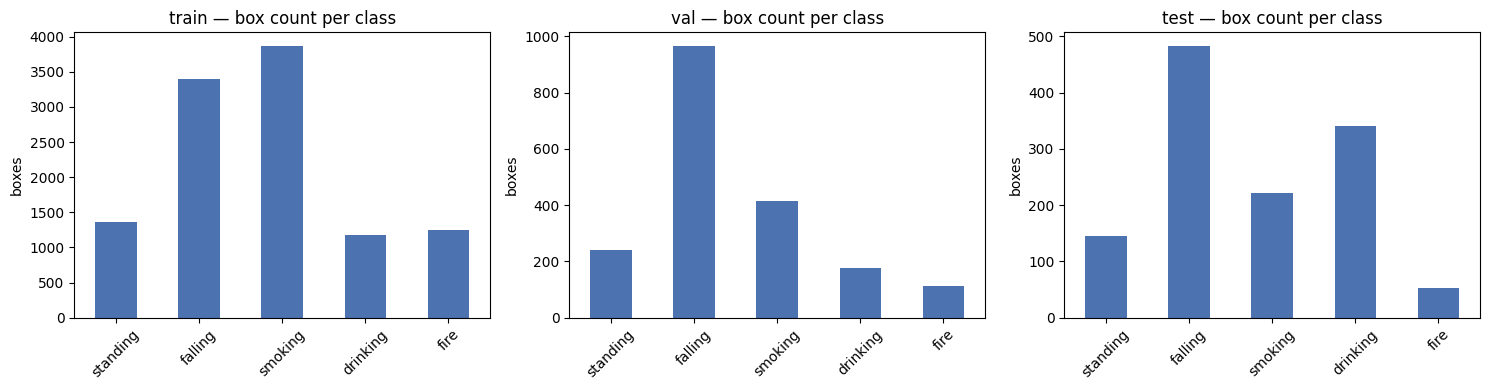


Check this before training:
  - Every class you care about should have a non-trivial bar in 'train'.
  - A class with 0 boxes anywhere means a source/class_map mismatch — fix SOURCES above.
  - Heavily imbalanced classes (10x+ difference) will bias the model; consider
    adding more data for the underrepresented class, or using class weighting.


In [12]:
def class_distribution(dataset_dir: Path, split: str, classes: list[str]) -> pd.Series:
    counts = {c: 0 for c in classes}
    lbl_dir = dataset_dir / split / "labels"
    for lbl_path in lbl_dir.glob("*.txt"):
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                counts[classes[int(parts[0])]] += 1
    return pd.Series(counts)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, split in zip(axes, ("train", "val", "test")):
    dist = class_distribution(MERGED_DATASET_DIR, split, UNIFIED_CLASSES)
    dist.plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(f"{split} — box count per class")
    ax.set_ylabel("boxes")
    for tick in ax.get_xticklabels():
        tick.set_rotation(45)
plt.tight_layout()
plt.show()

print("\nCheck this before training:")
print("  - Every class you care about should have a non-trivial bar in 'train'.")
print("  - A class with 0 boxes anywhere means a source/class_map mismatch — fix SOURCES above.")
print("  - Heavily imbalanced classes (10x+ difference) will bias the model; consider")
print("    adding more data for the underrepresented class, or using class weighting.")

In [13]:
import random

def undersample_pure_class(
    dataset_dir: Path, 
    target_class_name: str, 
    unified_classes: list[str], 
    max_boxes: int = 4000
) -> None:
    """
    Mitigates severe class imbalance by randomly downsampling training images 
    that EXCLUSIVELY contain the target overrepresented class. Images containing 
    mixed targets are fully preserved to protect minority class data representation.
    
    Args:
        dataset_dir (Path): Unified dataset root containing the train split.
        target_class_name (str): Name of the overrepresented class to cap (e.g., 'fire').
        unified_classes (list[str]): Current global taxonomy configuration list.
        max_boxes (int): The maximum acceptable target threshold cap. Defaults to 4000.
    """
    if target_class_name not in unified_classes:
        print(f"[WARN] Target class '{target_class_name}' is not in global taxonomy. Downsampling bypassed.")
        return
        
    target_id = unified_classes.index(target_class_name)
    train_lbl_dir = dataset_dir / "train" / "labels"
    train_img_dir = dataset_dir / "train" / "images"
    
    if not train_lbl_dir.exists():
        print("[ERROR] Merged training directory missing. Please execute Section 2 first.")
        return

    pure_target_files = []   # Contains only the target class (safe for pruning)
    mixed_target_files = []  # Contains the target class alongside other minority classes (protected)
    other_files_count = 0
    
    label_files = list(train_lbl_dir.glob("*.txt"))
    
    # Profile bounding box distributions across the train split
    for lbl_path in label_files:
        with open(lbl_path, "r") as f:
            class_ids = [int(line.strip().split()[0]) for line in f if line.strip()]
        
        if target_id in class_ids:
            if set(class_ids) == {target_id}:
                pure_target_files.append(lbl_path)
            else:
                mixed_target_files.append(lbl_path)
        else:
            other_files_count += 1

    initial_total_images = len(pure_target_files) + len(mixed_target_files)
    print("Dataset Imbalance Profile Before Undersampling:")
    print(f"  - Total frames containing '{target_class_name}': {initial_total_images}")
    print(f"  - Pure '{target_class_name}' files (Eligible for pruning): {len(pure_target_files)}")
    print(f"  - Mixed contextual files (Locked / Protected): {len(mixed_target_files)}")
    print(f"  - Target budget cap limit: {max_boxes}")

    # Calculate exact redundancy and remove random uniform entries
    if initial_total_images > max_boxes:
        allowed_pure_slots = max(0, max_boxes - len(mixed_target_files))
        num_to_delete = len(pure_target_files) - allowed_pure_slots
        
        if num_to_delete > 0:
            print(f"\n[INFO] Pruning dataset imbalance: Randomly selecting {num_to_delete} pure '{target_class_name}' images...")
            files_to_delete = random.sample(pure_target_files, num_to_delete)
            
            deleted_count = 0
            for lbl_path in files_to_delete:
                # Remove label file
                lbl_path.unlink()
                
                # Check and clean up the matching image across all standard extensions
                image_purged = False
                for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.PNG']:
                    img_path = train_img_dir / f"{lbl_path.stem}{ext}"
                    if img_path.exists():
                        img_path.unlink()
                        image_purged = True
                        break
                deleted_count += 1
            
            print(f"[SUCCESS] Dataset balanced successfully. Pruned {deleted_count} redundant images.")
        else:
            print("\n[INFO] Minority classes occupy the targeted capacity. Skipping pure file pruning.")
    else:
        print(f"\n[INFO] Target count for '{target_class_name}' is within normal parameters. Balancing skipped.")


# ── Run Dataset Balancing Pipeline ─────────────────────────────────────────
# Cap applies to 'fire'; raise max_boxes if the sanity-check plot above
# shows fire as comparatively underrepresented instead.
undersample_pure_class(
    dataset_dir=MERGED_DATASET_DIR,
    target_class_name="fire",
    unified_classes=UNIFIED_CLASSES,
    max_boxes=4000  # Caps total fire entries to protect minority action weights
)

Dataset Imbalance Profile Before Undersampling:
  - Total frames containing 'fire': 626
  - Pure 'fire' files (Eligible for pruning): 626
  - Mixed contextual files (Locked / Protected): 0
  - Target budget cap limit: 4000

[INFO] Target count for 'fire' is within normal parameters. Balancing skipped.


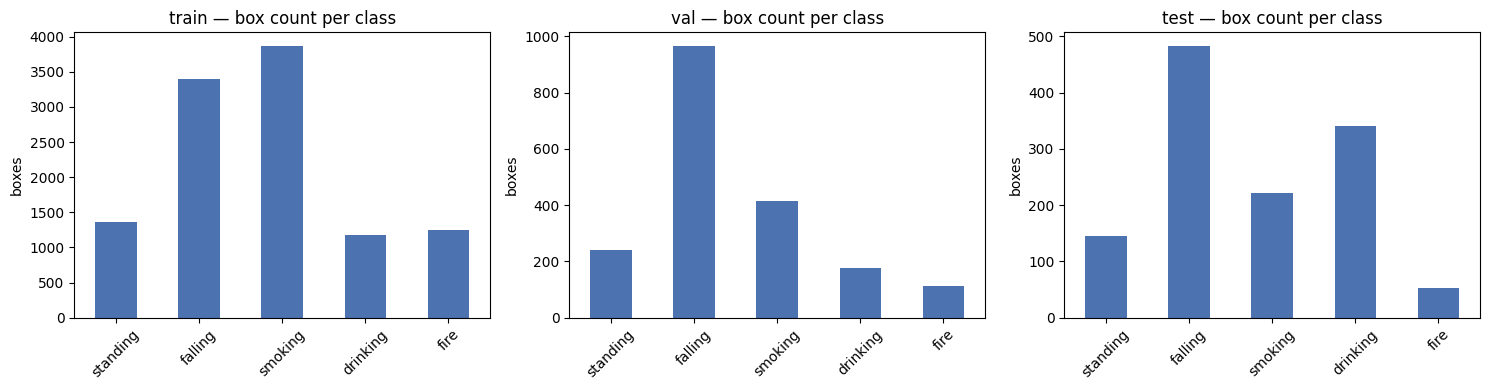


Check this before training:
  - Every class you care about should have a non-trivial bar in 'train'.
  - A class with 0 boxes anywhere means a source/class_map mismatch — fix SOURCES above.
  - Heavily imbalanced classes (10x+ difference) will bias the model; consider
    adding more data for the underrepresented class, or using class weighting.


In [14]:
def class_distribution(dataset_dir: Path, split: str, classes: list[str]) -> pd.Series:
    counts = {c: 0 for c in classes}
    lbl_dir = dataset_dir / split / "labels"
    for lbl_path in lbl_dir.glob("*.txt"):
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                counts[classes[int(parts[0])]] += 1
    return pd.Series(counts)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, split in zip(axes, ("train", "val", "test")):
    dist = class_distribution(MERGED_DATASET_DIR, split, UNIFIED_CLASSES)
    dist.plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(f"{split} — box count per class")
    ax.set_ylabel("boxes")
    for tick in ax.get_xticklabels():
        tick.set_rotation(45)
plt.tight_layout()
plt.show()

print("\nCheck this before training:")
print("  - Every class you care about should have a non-trivial bar in 'train'.")
print("  - A class with 0 boxes anywhere means a source/class_map mismatch — fix SOURCES above.")
print("  - Heavily imbalanced classes (10x+ difference) will bias the model; consider")
print("    adding more data for the underrepresented class, or using class weighting.")

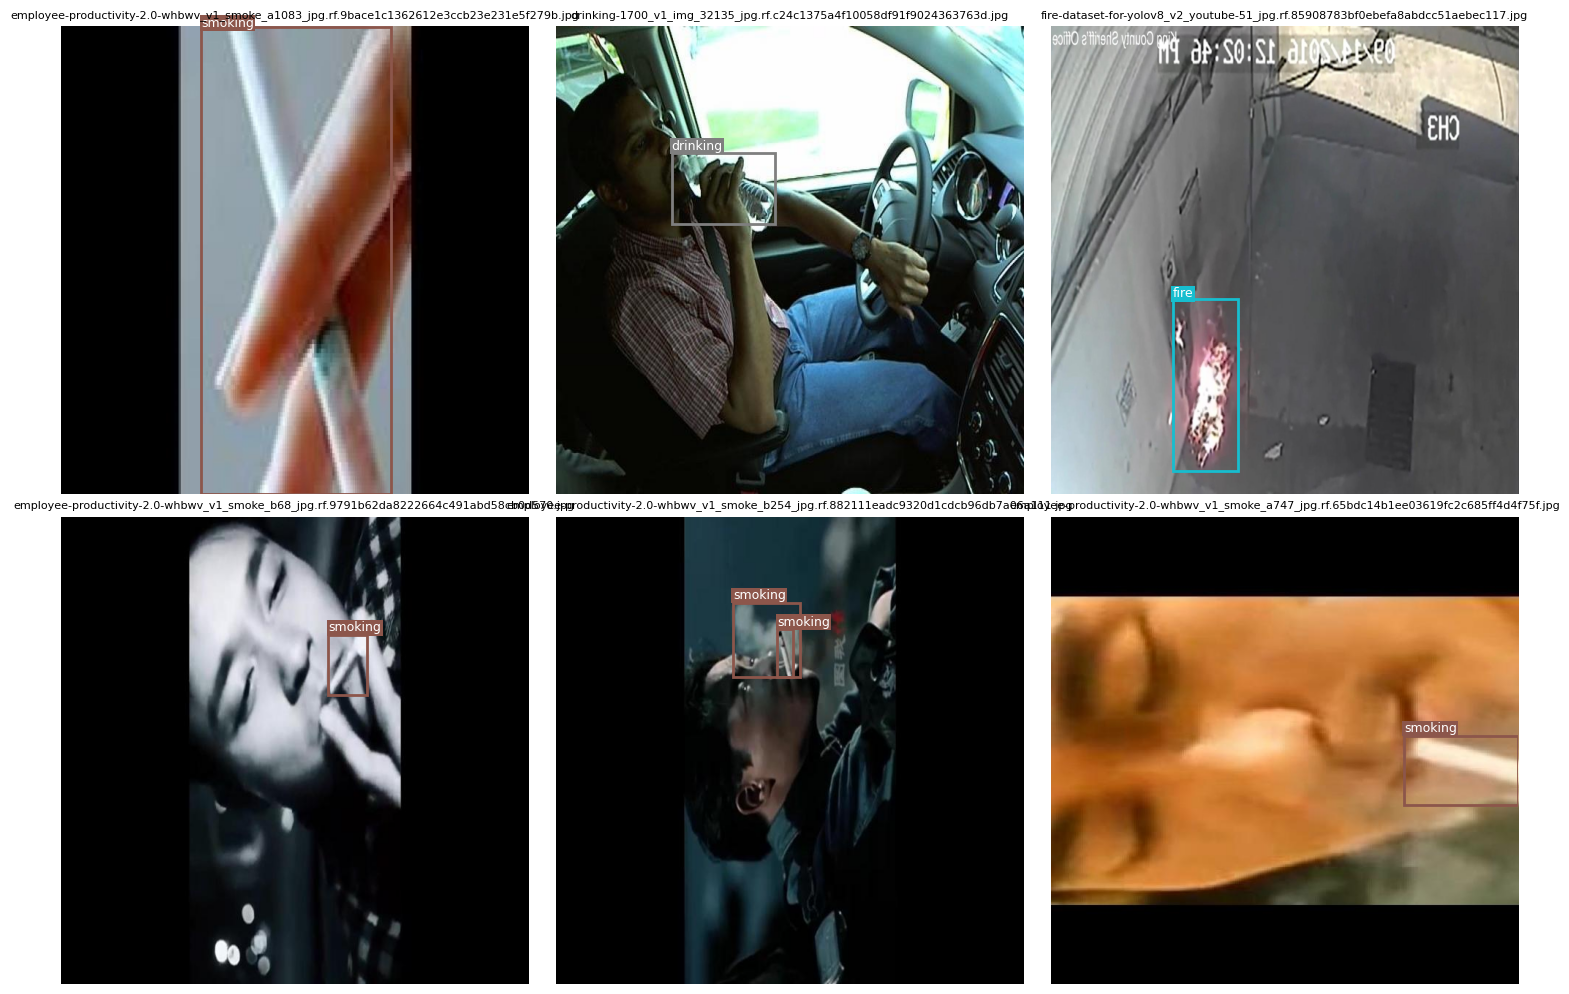

In [15]:
def show_sample_annotations(dataset_dir: Path, split: str, classes: list[str], n: int = 6, seed: int = SEED):
    img_dir = dataset_dir / split / "images"
    lbl_dir = dataset_dir / split / "labels"
    img_paths = sorted(img_dir.glob("*"))
    if not img_paths:
        print(f"No images found in {split}.")
        return

    rng = random.Random(seed)
    sample = rng.sample(img_paths, k=min(n, len(img_paths)))

    cols = 3
    rows = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
    axes = np.atleast_1d(axes).flatten()

    colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

    for ax, img_path in zip(axes, sample):
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        lbl_path = lbl_dir / (img_path.stem + ".txt")

        ax.imshow(img)
        if lbl_path.exists():
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls_id, cx, cy, bw, bh = int(parts[0]), *map(float, parts[1:5])
                    x1, y1 = (cx - bw / 2) * w, (cy - bh / 2) * h
                    rect_w, rect_h = bw * w, bh * h
                    ax.add_patch(plt.Rectangle(
                        (x1, y1), rect_w, rect_h, fill=False,
                        edgecolor=colors[cls_id], linewidth=2,
                    ))
                    ax.text(x1, max(y1 - 5, 0), classes[cls_id], color="white",
                             fontsize=9, bbox=dict(facecolor=colors[cls_id], pad=1, edgecolor="none"))
        ax.set_title(img_path.name, fontsize=8)
        ax.axis("off")

    for ax in axes[len(sample):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_sample_annotations(MERGED_DATASET_DIR, "train", UNIFIED_CLASSES, n=6)

In [16]:
# data.yaml for the merged dataset
data_yaml_path = MERGED_DATASET_DIR / "data.yaml"
data_yaml = {
    "path": str(MERGED_DATASET_DIR),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "nc": len(UNIFIED_CLASSES),
    "names": UNIFIED_CLASSES,
}
with open(data_yaml_path, "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print(data_yaml_path.read_text())

path: /kaggle/working/dataset
train: train/images
val: val/images
test: test/images
nc: 5
names:
- standing
- falling
- smoking
- drinking
- fire



## 4. Training configuration

Hyperparameters below are chosen for **accuracy on a small nano model**,
balancing Kaggle's session time limits (9h GPU quota per session):

- `imgsz=640` — full resolution training; export a smaller size later for the edge device.
- `epochs=150` + `patience=30` — early stopping prevents wasted epochs once validation mAP plateaus.
- `cos_lr=True` — cosine LR schedule generally converges to a better optimum than linear decay.
- `close_mosaic=10` — disables mosaic augmentation for the last 10 epochs, which stabilizes
  bounding-box regression late in training (a well-known accuracy trick for YOLOv8).
- `mixup=0.1`, `degrees`, `translate`, `scale`, `fliplr` — moderate augmentation to
  improve generalization without distorting small/rare classes too much.
- `label_smoothing` is intentionally left at Ultralytics' default (0.0) — with only a
  handful of classes it rarely helps and can blur close classes like `smoking`/`drinking`.


In [17]:
@dataclass
class TrainConfig:
    base_model: str = "yolov8n.pt"     # nano checkpoint pretrained on COCO
    data_yaml: str = str(data_yaml_path)
    imgsz: int = 640
    epochs: int = 150
    patience: int = 30
    batch: int = 16                     # reduce if you hit CUDA OOM
    optimizer: str = "auto"
    cos_lr: bool = True
    close_mosaic: int = 10
    mixup: float = 0.1
    degrees: float = 5.0
    translate: float = 0.1
    scale: float = 0.5
    fliplr: float = 0.5
    seed: int = SEED
    project: str = "/kaggle/working/runs"
    name: str = "yolov8n_safety_actions"


cfg = TrainConfig()
cfg

TrainConfig(base_model='yolov8n.pt', data_yaml='/kaggle/working/dataset/data.yaml', imgsz=640, epochs=150, patience=30, batch=16, optimizer='auto', cos_lr=True, close_mosaic=10, mixup=0.1, degrees=5.0, translate=0.1, scale=0.5, fliplr=0.5, seed=42, project='/kaggle/working/runs', name='yolov8n_safety_actions')

## 5. Training

In [18]:
model = YOLO(cfg.base_model)

results = model.train(
    data=cfg.data_yaml,
    imgsz=cfg.imgsz,
    epochs=cfg.epochs,
    patience=cfg.patience,
    batch=cfg.batch,
    optimizer=cfg.optimizer,
    cos_lr=cfg.cos_lr,
    close_mosaic=cfg.close_mosaic,
    mixup=cfg.mixup,
    degrees=cfg.degrees,
    translate=cfg.translate,
    scale=cfg.scale,
    fliplr=cfg.fliplr,
    seed=cfg.seed,
    project=cfg.project,
    name=cfg.name,
    exist_ok=True,
    plots=True,
    verbose=True,
)

RUN_DIR = Path(cfg.project) / cfg.name
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
print(f"\nBest weights saved to: {BEST_WEIGHTS}")

Ultralytics 8.4.92 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/dataset/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_safety_actions, nbs=64, nms=False, opset=None, optimize=False, optimizer=a

## 6. Evaluation & diagnostics

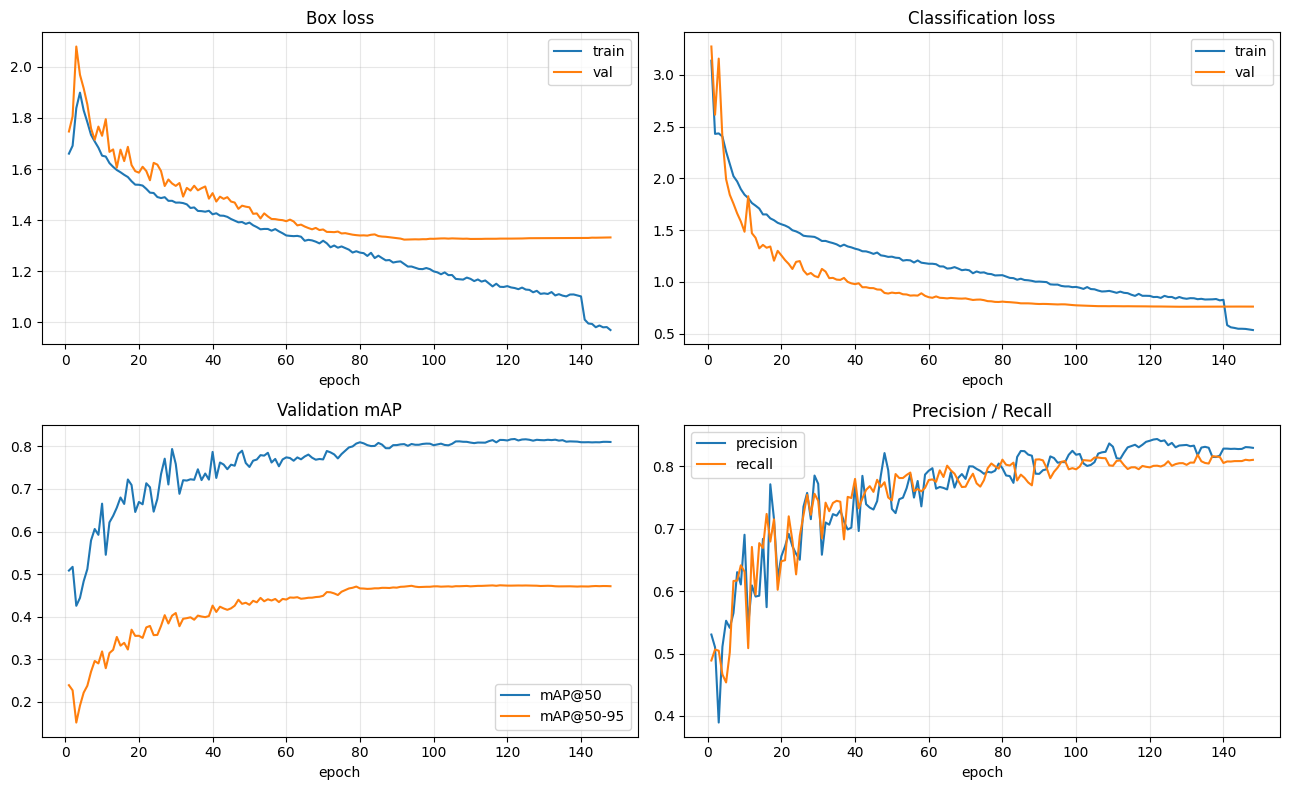

In [19]:
results_csv = RUN_DIR / "results.csv"
history = pd.read_csv(results_csv)
history.columns = [c.strip() for c in history.columns]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(history["epoch"], history["train/box_loss"], label="train")
axes[0, 0].plot(history["epoch"], history["val/box_loss"], label="val")
axes[0, 0].set_title("Box loss")
axes[0, 0].legend()

axes[0, 1].plot(history["epoch"], history["train/cls_loss"], label="train")
axes[0, 1].plot(history["epoch"], history["val/cls_loss"], label="val")
axes[0, 1].set_title("Classification loss")
axes[0, 1].legend()

axes[1, 0].plot(history["epoch"], history["metrics/mAP50(B)"], label="mAP@50")
axes[1, 0].plot(history["epoch"], history["metrics/mAP50-95(B)"], label="mAP@50-95")
axes[1, 0].set_title("Validation mAP")
axes[1, 0].legend()

axes[1, 1].plot(history["epoch"], history["metrics/precision(B)"], label="precision")
axes[1, 1].plot(history["epoch"], history["metrics/recall(B)"], label="recall")
axes[1, 1].set_title("Precision / Recall")
axes[1, 1].legend()

for ax in axes.flat:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
best_model = YOLO(str(BEST_WEIGHTS))
metrics = best_model.val(data=cfg.data_yaml, split="test", plots=True)

print(f"mAP50    : {metrics.box.map50:.4f}")
print(f"mAP50-95 : {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall   : {metrics.box.mr:.4f}")

print("\nPer-class AP@50:")
for cls_id, ap in zip(metrics.box.ap_class_index, metrics.box.ap50):
    print(f"  {UNIFIED_CLASSES[cls_id]:>10s}: {ap:.4f}")

Ultralytics 8.4.92 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 899.6±356.9 MB/s, size: 42.0 KB)
val: Scanning /kaggle/working/dataset/test/labels... 1160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1160/1160 1.3Kit/s 0.9s
val: New cache created: /kaggle/working/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 8.4it/s 8.7s
                   all       1160       1244      0.909      0.846      0.891      0.531
              standing         90        146      0.934      0.969      0.985      0.684
               falling        483        483      0.864      0.825      0.892      0.589
               smoking        195        222      0.819      0.631      0.728      0.368
              drinking        340        340      0.996      0.997     

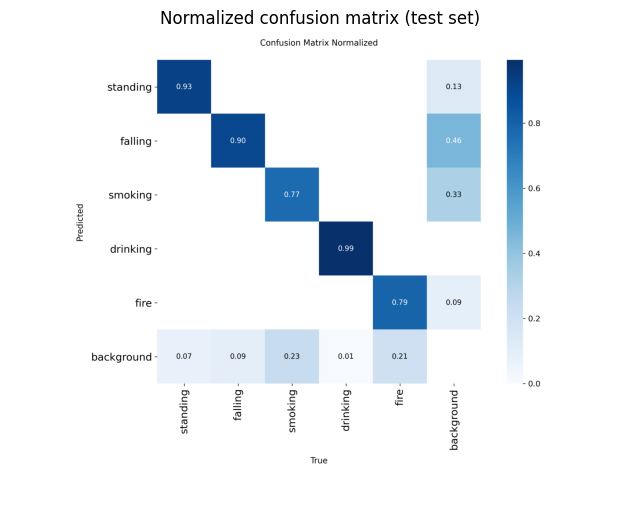

In [21]:
confusion_matrix_path = RUN_DIR / "confusion_matrix_normalized.png"
if confusion_matrix_path.exists():
    img = cv2.cvtColor(cv2.imread(str(confusion_matrix_path)), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Normalized confusion matrix (test set)")
    plt.show()

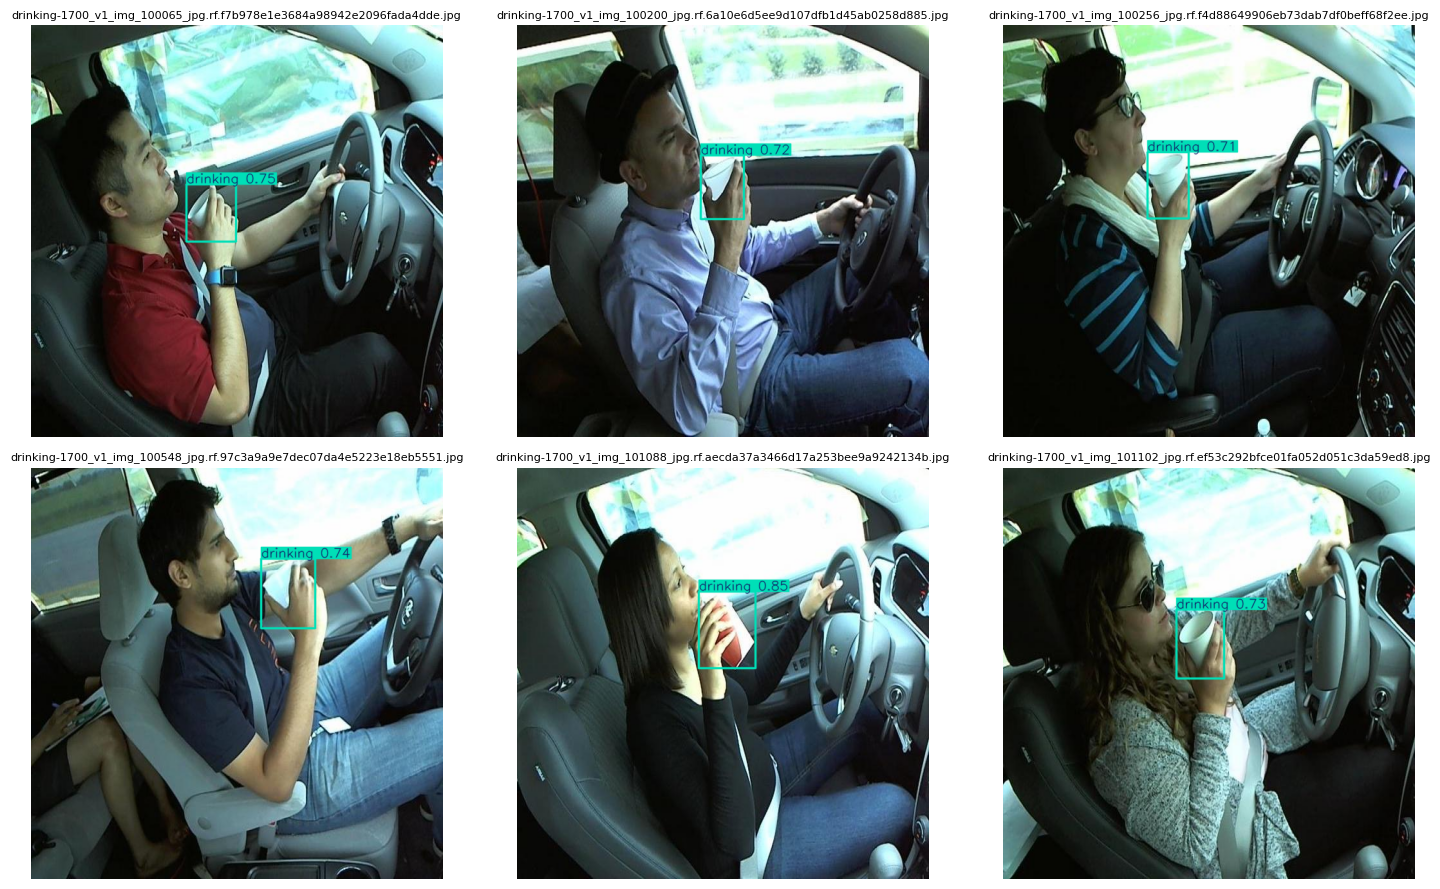

In [22]:
# Qualitative check: run the trained model on a handful of test images
test_images = sorted((MERGED_DATASET_DIR / "test" / "images").glob("*"))[:6]
if test_images:
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, img_path in zip(axes.flat, test_images):
        pred = best_model.predict(str(img_path), conf=0.35, verbose=False)[0]
        annotated = pred.plot()[:, :, ::-1]  # BGR -> RGB
        ax.imshow(annotated)
        ax.set_title(img_path.name, fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No test images found — skipping qualitative check.")

## 7. Export (ONNX, for edge deployment)

Exporting at **imgsz=320** matches the inference size used for edge
deployment — smaller input size trades a little accuracy for a large speed
gain on CPU-only edge hardware. A 640px export is also produced in case you
deploy on something with more headroom (e.g. a Coral/Jetson/desktop GPU).


In [23]:
# Both exports write to the same file (weights/best.onnx), so copy each one to
# its own name immediately — otherwise the 640 export overwrites the 320 one.
# (Fixed after the run shown below: in that run, best_320.onnx ended up being a
#  copy of the 640 model.)
onnx_320 = RUN_DIR / "weights" / "best_320.onnx"
shutil.copy(best_model.export(format="onnx", imgsz=320, opset=12, simplify=True), onnx_320)

onnx_640 = RUN_DIR / "weights" / "best_640.onnx"
shutil.copy(best_model.export(format="onnx", imgsz=640, opset=12, simplify=True), onnx_640)

print(f"320px ONNX export: {onnx_320}")
print(f"640px ONNX export: {onnx_640}")

Ultralytics 8.4.92 🚀 Python-3.12.13 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from '/kaggle/working/runs/yolov8n_safety_actions/weights/best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 9, 2100) (6.0 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 12 packages in 386ms
 Downloaded onnxruntime
Prepared 2 packages in 304ms
Installed 2 packages in 15ms
 + onnxruntime==1.27.0
 + onnxslim==0.1.94

requirements: AutoUpdate success ✅ 1.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 12...
ONNX: slimming with onnxslim 0.1.94...
ONNX: export success ✅ 3.1s, saved as '/kaggle/working/runs/yolov8n_safety_acti

## 8. Packaging outputs

In [24]:
EXPORT_DIR = Path("/kaggle/working/export")
EXPORT_DIR.mkdir(exist_ok=True)

shutil.copy(BEST_WEIGHTS, EXPORT_DIR / "best.pt")
shutil.copy(onnx_320, EXPORT_DIR / "best_320.onnx")
shutil.copy(onnx_640, EXPORT_DIR / "best_640.onnx")
shutil.copy(data_yaml_path, EXPORT_DIR / "data.yaml")
if (RUN_DIR / "results.png").exists():
    shutil.copy(RUN_DIR / "results.png", EXPORT_DIR / "results.png")
if confusion_matrix_path.exists():
    shutil.copy(confusion_matrix_path, EXPORT_DIR / "confusion_matrix.png")

archive_path = shutil.make_archive("/kaggle/working/yolov8n_safety_export", "zip", EXPORT_DIR)
print(f"Packaged export ready at: {archive_path}")
print("\nFiles included:")
for p in sorted(EXPORT_DIR.iterdir()):
    print(f"  - {p.name}")

Packaged export ready at: /kaggle/working/yolov8n_safety_export.zip

Files included:
  - best.pt
  - best_320.onnx
  - best_640.onnx
  - confusion_matrix.png
  - data.yaml
  - results.png


### Getting the zip out of Kaggle (fix for "I can't get outputs")

If the **Output** tab on Kaggle is empty even after this cell ran, it's
almost always because the notebook was only run interactively, not
committed. Use whichever of these fits your situation:

**Fastest — direct download link, no commit needed:**
Run the cell right below. It renders a clickable link in the notebook output
itself that downloads the zip straight from your current interactive
session — works immediately, no waiting on the Output tab.

**For a persistent copy in the Output tab:**
Click **Save Version** (top right) → choose **Save & Run All (Commit)** →
wait for it to finish executing top-to-bottom → then open that saved
version's **Output** tab. The zip will be listed there and stays available
after the session ends. (A "Quick Save" does *not* populate the Output tab —
it must be "Save & Run All".)


In [25]:
from IPython.display import FileLink

# Direct in-notebook download link — works in an interactive session,
# no need to wait for a committed Output tab.
FileLink(archive_path)

/kaggle/working/yolov8n_safety_export.zip

### Next steps

1. Download `yolov8n_safety_export.zip` via the `FileLink` above, or from the
   Kaggle **Output** tab after committing.
2. Copy the ONNX model into the repo's `models/` folder and run
   `src/detector_pi5.py` on the Raspberry Pi 5 (input size is auto-detected).
3. Test each class live with `src/detect_webcam.py` and tune `--conf`.
4. If per-class AP in Section 6 is weak for any class, that's almost always a
   **data** problem, not a hyperparameter problem — check the Section 3
   class-distribution plot first to confirm each source contributed a
   meaningful number of boxes, before adding another source or tuning further.